# CLFG · WY2026 snow depth with and without spin-up

Compare the original snow-free WY2026 runs with runs started in WY2020. For each forcing, the WY2026 hourly weather is identical between the two runs. The longer runs carry their simulated snowpack into WY2026. This comparison excludes older layers **in post-processing** so their effects on the evolving snowpack remain in the simulation.

The only field observation is approximately **2 m on May 25, 2026**. Its hour is unknown, so we compare the 24 hours of that Juneau calendar day. The source archive ends on September 29, 2026.

The longer lapse-rate simulation uses the [radar-site empty-column numerical guard](../../radar_sites/numerics/README.md). It triggered once in WY2020; the first 160 hourly depth and SWE values matched the interrupted run exactly. The source is missing one hour on May 23, 2024, which stays missing in the forcing.

To reproduce the longer runs in a separate model directory, use `python sites/clfg/scripts/run_clfg.py --start-water-year 2020 --empty-column-guard hrrrak_lapserate --output-root /path/to/runs`. Then set `CLFG_SPINUP_SITE` to that directory's `clfg` subfolder.

In [1]:
import json
import mmap
import os
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'sites/clfg/site_info.txt').is_file()), None)
if root is None:
    raise RuntimeError('Open from inside jif_snow_modeling')
sys.path.insert(0, str(root / 'sites/radar_sites/scripts'))
from compare_model_pit_radar import FORCINGS, autumn_adjustments
from prepare_radar_site_forcing import MODEL_ROOT, read_smet
from visualization import OBSERVATION_COLOR, RC_PARAMS, SIMULATION_COLORS, SIMULATION_LABELS

plt.rcParams.update(RC_PARAMS)
site_dir = Path(os.environ.get('CLFG_MODEL_SITE', MODEL_ROOT / 'clfg')).expanduser()
spinup_dir = Path(os.environ.get('CLFG_SPINUP_SITE', site_dir)).expanduser()
single_period, spinup_period = 'WY2026', 'WY2020-WY2026'
season_start = pd.Timestamp('2025-10-01T00:00:00')
timezone = 'America/Juneau'
info = dict(line.split(': ', 1) for line in (root / 'sites/clfg/site_info.txt').read_text().splitlines())
observation_day = pd.Timestamp(info['Observation date'], tz=timezone)
next_day = observation_day + pd.DateOffset(days=1)
observed_depth = float(info['Snow depth'].split()[1])

def run_path(directory, period, forcing, suffix):
    station = f'{forcing}_clfg_{period}'
    return directory / 'output' / f'{station}_heatflux_soiltemp_zero.{suffix}'

def load_run(directory, period, forcing):
    station = f'{forcing}_clfg_{period}'
    stem = directory / 'input' / f'{forcing}_{period}' / station
    metadata = json.loads(stem.with_suffix('.json').read_text())
    expected = pd.date_range(metadata['start_UTC'], metadata['end_UTC'], freq='h')
    _, forcing_frame = read_smet(stem.with_suffix('.smet'))
    header, model = read_smet(run_path(directory, period, forcing, 'smet'), ['timestamp', 'HS_mod'])
    depth_unit = header['units_multiplier'].split()[header['fields'].split().index('HS_mod')]
    if float(depth_unit) != 0.01:
        raise ValueError('Expected model depth stored in cm')
    if not model.index.equals(expected) or not np.isfinite(model.to_numpy()).all():
        raise ValueError(f'Incomplete model output for {station}')
    return forcing_frame, model.rename(columns={'HS_mod': 'depth_cm'})

single, spinup = {}, {}
for forcing in FORCINGS:
    one_year_forcing, single[forcing] = load_run(site_dir, single_period, forcing)
    long_forcing, spinup[forcing] = load_run(spinup_dir, spinup_period, forcing)
    pd.testing.assert_frame_equal(one_year_forcing, long_forcing.loc[season_start:], check_freq=False)
    if not single[forcing].index.equals(spinup[forcing].loc[season_start:].index):
        raise ValueError(f'WY2026 model times disagree for {forcing}')
print('Verified the same WY2026 forcing and output times in each pair.')


Verified the same WY2026 forcing and output times in each pair.


## Remove pre-WY2026 snow from the depth comparison

For each hourly profile, sum the thickness of layers whose native SNOWPACK age is no greater than the elapsed time since October 1, 2025 UTC. This gives an estimate of snow added during WY2026. It cannot track exact deposition boundaries inside layers that have merged, and it does not diagnose firn from density. Compare it with the radar-site sensitivity method, which subtracts a fixed August–October 2025 minimum depth. Fixed-baseline results can be negative if total depth drops below that minimum later in the year.

In [2]:
def layer_depths(path, start):
    records = []

    def append_profile(time, tops, ages):
        if tops is None:
            raise ValueError(f'Missing layer heights at {time} in {path}')
        if len(tops) == 1 and tops[0] == 0:
            records.append((time, 0.0, 0.0))
            return
        if (ages is None or len(ages) != len(tops) or
                not np.isfinite(tops).all() or not np.isfinite(ages).all() or
                (ages < 0).any()):
            raise ValueError(f'Invalid layer ages or heights at {time} in {path}')
        thickness = np.diff(np.r_[0, tops])
        if (thickness < 0).any():
            raise ValueError(f'Nonmonotonic snow-layer heights at {time} in {path}')
        elapsed_days = (time - start) / pd.Timedelta(days=1)
        current = thickness[ages <= elapsed_days].sum()
        records.append((time, tops[-1], current))

    with path.open('rb') as stream, mmap.mmap(stream.fileno(), 0, access=mmap.ACCESS_READ) as data:
        first = data.find(start.strftime('0500,%d.%m.%Y %H:%M:%S').encode())
        if first == -1:
            raise ValueError(f'No profile at {start} in {path}')
        data.seek(first)
        time = None
        for line in iter(data.readline, b''):
            if line.startswith(b'0500,'):
                if time is not None:
                    append_profile(time, tops, ages)
                time = pd.to_datetime(line[5:].decode().strip(), format='%d.%m.%Y %H:%M:%S')
                tops = ages = None
            elif line.startswith((b'0501,', b'0505,')):
                field, count, payload = line.split(b',', 2)
                values = np.fromstring(payload.decode(), sep=',')
                if len(values) != int(count):
                    raise ValueError(f'Wrong element count at {time} in {path}')
                if field == b'0501':
                    tops = values
                else:
                    ages = values
        append_profile(time, tops, ages)
    return pd.DataFrame(records, columns=['time', 'profile_depth_cm', 'current_depth_cm']).set_index('time')


baseline_runs, baseline_audit = autumn_adjustments({('clfg', f): run for f, run in spinup.items()})
baselines = baseline_audit.loc[baseline_audit.water_year.eq(2026)]
if not baselines.complete.all():
    raise ValueError('Expected complete August–October baseline windows')
display(baselines[['forcing', 'autumn_minimum_cm', 'minimum_date']].round(2))

comparison = {}
for forcing in FORCINGS:
    layers = layer_depths(run_path(spinup_dir, spinup_period, forcing, 'pro'), season_start)
    short = single[forcing].depth_cm
    full = spinup[forcing].loc[season_start:, 'depth_cm']
    if not layers.index.equals(short.index):
        raise ValueError(f'Profile and time-series hours disagree for {forcing}')
    np.testing.assert_allclose(layers.profile_depth_cm, full, rtol=0, atol=.011)
    frame = pd.DataFrame({
        'Single year': short,
        'Spin-up · total column': full,
        'Spin-up · WY2026 layers': layers.current_depth_cm,
        'Spin-up · autumn minimum removed': baseline_runs['clfg', forcing].loc[season_start:, 'depth_above_minimum_cm'],
    }) / 100
    frame.index = frame.index.tz_localize('UTC').tz_convert(timezone)
    comparison[forcing] = frame


,forcing,autumn_minimum_cm,minimum_date
6,hrrrak,0.0,2025-09-11 20:00:00
13,hrrrak_lapserate,0.0,2025-08-01 00:00:00


In [3]:
rows = []
for forcing, frame in comparison.items():
    day = frame.loc[(frame.index >= observation_day) & (frame.index < next_day)]
    if len(day) != 24:
        raise ValueError(f'Expected 24 local observation-day hours for {forcing}')
    for label, values in day.items():
        rows.append({
            'Forcing': SIMULATION_LABELS[forcing],
            'Depth series': label,
            'May 25 mean (m)': values.mean(),
            'May 25 min (m)': values.min(),
            'May 25 max (m)': values.max(),
            'Mean minus single year (m)': values.mean() - day['Single year'].mean(),
            'Mean minus approx. 2 m (m)': values.mean() - observed_depth,
        })
display(pd.DataFrame(rows).round(2))


,Forcing,Depth series,May 25 mean (m),May 25 min (m),May 25 max (m),Mean minus single year (m),Mean minus approx. 2 m (m)
0,HRRR-AK Raw,Single year,6.02,6.00,6.03,0.00,4.02
1,HRRR-AK Raw,Spin-up · total column,6.12,6.10,6.13,0.10,4.12
2,HRRR-AK Raw,Spin-up · WY2026 layers,6.00,5.98,6.01,-0.02,4.00
3,HRRR-AK Raw,Spin-up · autumn minimum removed,6.12,6.10,6.13,0.10,4.12
4,HRRR-AK Lapserate,Single year,1.26,1.24,1.28,0.00,-0.74
5,HRRR-AK Lapserate,Spin-up · total column,1.26,1.24,1.28,0.00,-0.74
6,HRRR-AK Lapserate,Spin-up · WY2026 layers,1.26,1.24,1.28,-0.00,-0.74
7,HRRR-AK Lapserate,Spin-up · autumn minimum removed,1.26,1.24,1.28,0.00,-0.74


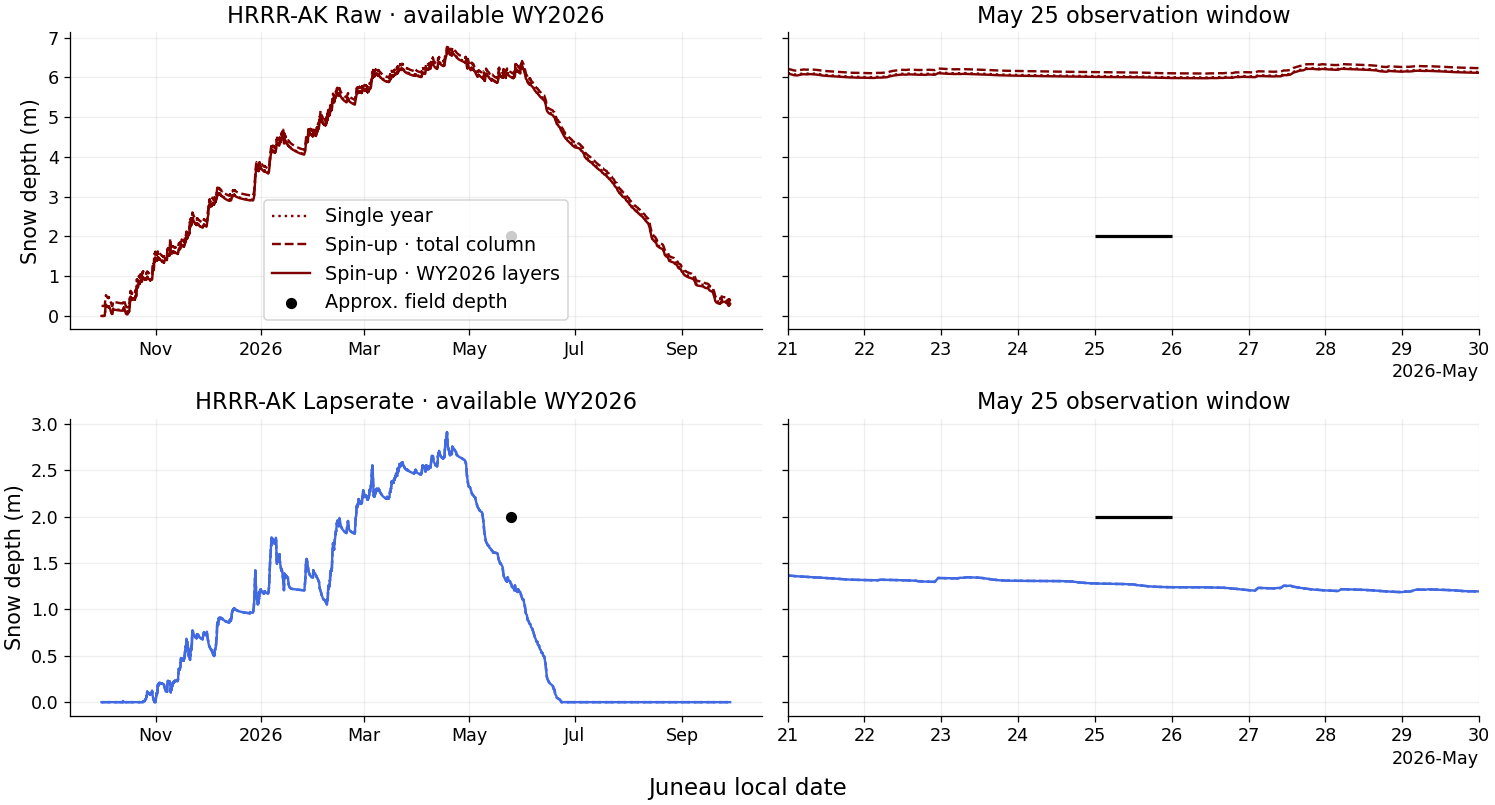

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey='row', layout='constrained')
styles = {'Single year': ':', 'Spin-up · total column': '--', 'Spin-up · WY2026 layers': '-'}
zoom_start = observation_day - pd.Timedelta(days=4)
zoom_end = next_day + pd.Timedelta(days=4)
for row, (forcing, frame) in enumerate(comparison.items()):
    full_ax, zoom_ax = axes[row]
    color = SIMULATION_COLORS[forcing]
    for label, style in styles.items():
        full_ax.plot(frame.index, frame[label], linestyle=style, color=color, label=label)
        zoom = frame.loc[zoom_start:zoom_end, label]
        zoom_ax.plot(zoom.index, zoom, linestyle=style, color=color)
    full_ax.scatter(observation_day + pd.Timedelta(hours=12), observed_depth,
                    color=OBSERVATION_COLOR, label='Approx. field depth', zorder=3)
    zoom_ax.hlines(observed_depth, observation_day, next_day, color=OBSERVATION_COLOR, linewidth=2)
    full_ax.set(title=f'{SIMULATION_LABELS[forcing]} · available WY2026', ylabel='Snow depth (m)')
    zoom_ax.set(title='May 25 observation window', xlim=(zoom_start, zoom_end))
    for ax in (full_ax, zoom_ax):
        locator = mdates.AutoDateLocator(tz=timezone)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone))
        ax.grid(alpha=.2)
axes[0, 0].legend()
fig.supxlabel('Juneau local date')
plt.show()
